In [1]:
import json
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm

rule_color_map = {
    "borda": "#1460bc",  # lightblue
    "3-approval": "#8cb500",  # applegreen
    "2-approval": "#218c21",  # forestgreen
    "plurality": "#d11942",  # alizarin
    "stv": "#ffc40c",  # mikadoyellow
    "ranked-pairs": "#ffb7c4",  # cherryblossompink
    "random": "#707f8e",  # slategray
}

In [2]:

all_files = glob("../../../stats/bt_proportionality/*.json")
df_list = []
for path in all_files:

    with open(path, "r") as f:
        data = json.load(f)

    rows = []
    for file_path, methods in data.items():
        for method, vals in methods.items():
            rows.append({
                "file": file_path,
                "method": method,
                "expected_proportion": vals.get("expected_proportion"),
                "observed_proportion": vals.get("observed_proportion"),
            })

    df_list.append(pd.DataFrame(rows))

df = pd.concat(df_list, ignore_index=True)
df["file"] = df["file"].str.split("/data/").str[1]
df

,file,method,expected_proportion,observed_proportion
0,preference_profiles/05_05/b_proportion_0.5__AL...,borda,0.500000,0.333333
1,preference_profiles/05_05/b_proportion_0.5__AL...,3-approval,0.500000,0.666667
2,preference_profiles/05_05/b_proportion_0.5__AL...,2-approval,0.500000,0.666667
3,preference_profiles/05_05/b_proportion_0.5__AL...,plurality,0.500000,0.666667
4,preference_profiles/05_05/b_proportion_0.5__AL...,stv,0.500000,0.666667
...,...,...,...,...
587995,preference_profiles/05_05/b_proportion_0.9__AL...,2-approval,0.888598,1.000000
587996,preference_profiles/05_05/b_proportion_0.9__AL...,plurality,0.888598,1.000000
587997,preference_profiles/05_05/b_proportion_0.9__AL...,stv,0.888598,1.000000
587998,preference_profiles/05_05/b_proportion_0.9__AL...,ranked-pairs,0.888598,1.000000


In [3]:
df["file"][0]

'preference_profiles/05_05/b_proportion_0.5__ALPHA_(0.50,0.50,0.50,0.50)__COHESION_(0.90,0.90)/profile_0.csv'

In [4]:
df["disprop"] = df["observed_proportion"] - df["expected_proportion"]

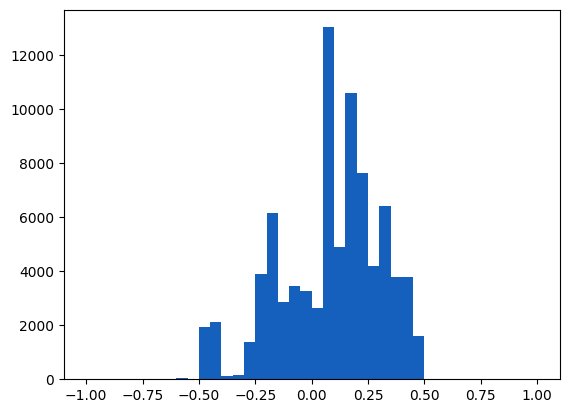

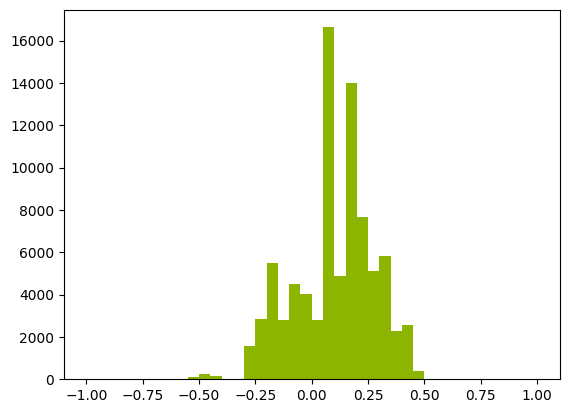

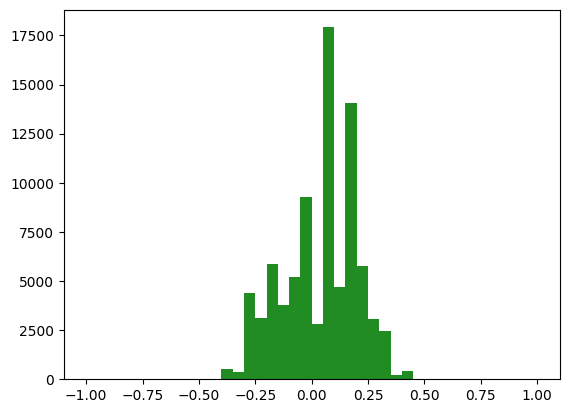

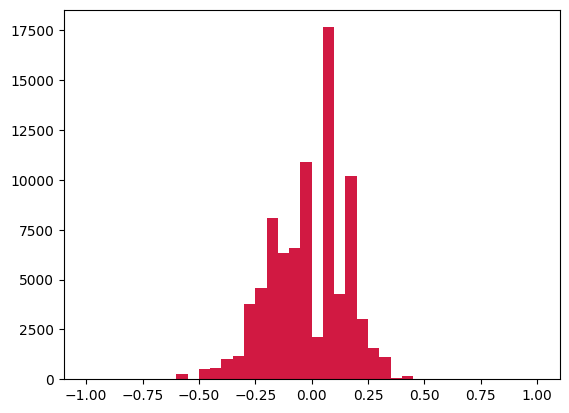

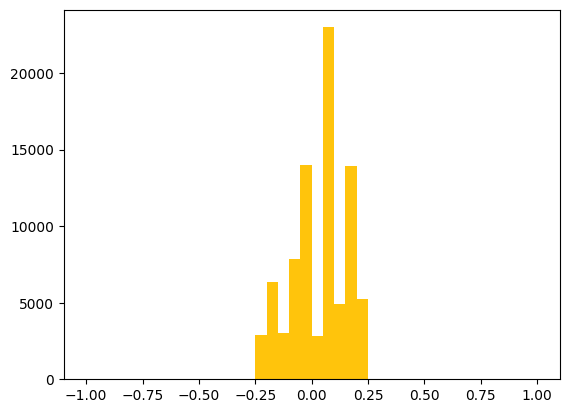

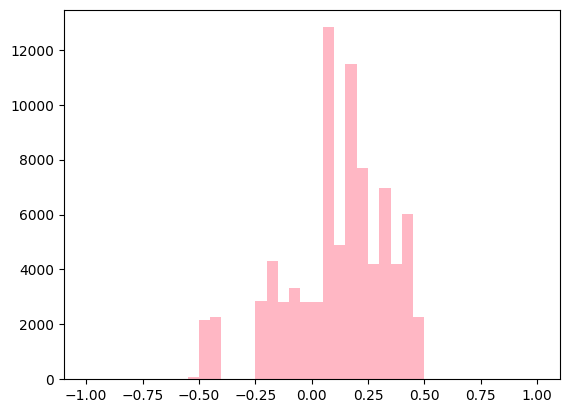

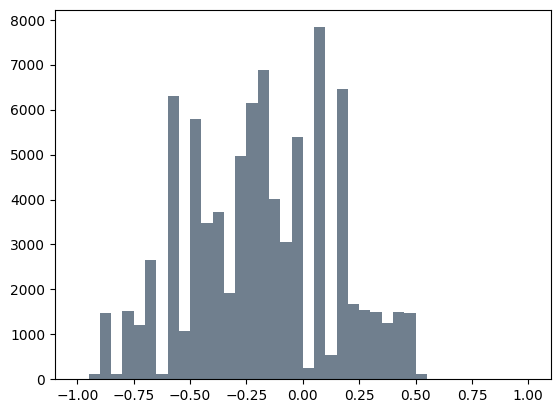

In [5]:
import numpy as np

AllowedRule = (
    "borda",
    "3-approval",
    "2-approval",
    "plurality",
    "stv",
    "ranked-pairs",
    "random"
)

for election_type in AllowedRule:
    rule_df = df.query("method == @election_type")
    _, ax = plt.subplots()
    ax.hist(rule_df["disprop"], color=rule_color_map[election_type], bins=np.arange(-1, 1.05, 0.05))
    # plt.savefig(f"../plots/bt_plots/disprop_histograms/{election_type}_disprop_hist.png", dpi=300, bbox_inches='tight')


In [6]:
from itertools import product



n_voters = 15_000
n_samples = 100

b_bloc_proportions = [0.5, 0.6, 0.7, 0.8, 0.9]
alpha_combinations = [
    (1, 1, 1, 1),
    (0.5, 0.5, 0.5, 0.5),
    (2, 2, 2, 2),
    (1, 0.5, 1, 0.5),
    (1, 2, 1, 2),
    (0.5, 1, 0.5, 1),
    (2, 1, 2, 1),
]
cohesion_combinations = [
    (0.7, 0.7),
    (0.7, 0.9),
    (0.9, 0.7),
    (0.9, 0.9),
]
candidate_count_combinations = [
    (2, 6),
    (4, 4),
    (6, 2),
    (2, 8),
    (5, 5),
    (8, 2),
]


all_settings_strings = dict()
for (n_a_cands, n_b_cands), b_bloc_proportion, (a_coh, b_coh), (
    aa_al,
    ab_al,
    ba_al,
    bb_al,
), i in product(
    candidate_count_combinations,
    b_bloc_proportions,
    cohesion_combinations,
    alpha_combinations,
    list(range(n_samples)),
):
    settings_str = (
        f"{n_a_cands:02d}_{n_b_cands:02d}/"
        f"b_proportion_{b_bloc_proportion}"
        f"__ALPHA_({aa_al:.2f},{ab_al:.2f},{ba_al:.2f},{bb_al:.2f})"
        f"__COHESION_({a_coh:.2f},{b_coh:.2f})"
    )
    all_settings_strings[settings_str] = True

list(all_settings_strings.keys())[0]

'02_06/b_proportion_0.5__ALPHA_(1.00,1.00,1.00,1.00)__COHESION_(0.70,0.70)'

In [7]:
N_SEATS = 3
for election_type in AllowedRule:
    rule_df = df.query("method == @election_type")
    print(f"RULE: {election_type}\n\tDISPROP MEAN: {rule_df['disprop'].mean()}\n\t|DISPROP| MEAN: {rule_df['disprop'].std()}")

RULE: borda
	DISPROP MEAN: 0.0887480511946517
	|DISPROP| MEAN: 0.2240294599354554
RULE: 3-approval
	DISPROP MEAN: 0.1026885273851279
	|DISPROP| MEAN: 0.1751948662614112
RULE: 2-approval
	DISPROP MEAN: 0.04018852738512789
	|DISPROP| MEAN: 0.16101524955826396
RULE: plurality
	DISPROP MEAN: -0.013940440868840364
	|DISPROP| MEAN: 0.16443374134944028
RULE: stv
	DISPROP MEAN: 0.03500400357560408
	|DISPROP| MEAN: 0.11860820342179382
RULE: ranked-pairs
	DISPROP MEAN: 0.12020836865496917
	|DISPROP| MEAN: 0.2234423588430946
RULE: random
	DISPROP MEAN: -0.184934488487888
	|DISPROP| MEAN: 0.3208171924714886


  0%|          | 0/840 [00:00<?, ?it/s]

  0%|          | 0/840 [00:00<?, ?it/s]

  0%|          | 0/840 [00:00<?, ?it/s]

  0%|          | 0/840 [00:00<?, ?it/s]

  0%|          | 0/840 [00:00<?, ?it/s]

  0%|          | 0/840 [00:00<?, ?it/s]

  0%|          | 0/840 [00:00<?, ?it/s]

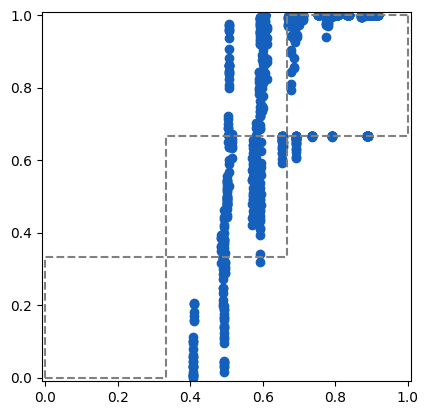

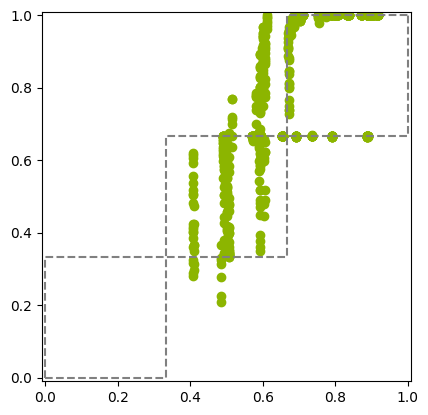

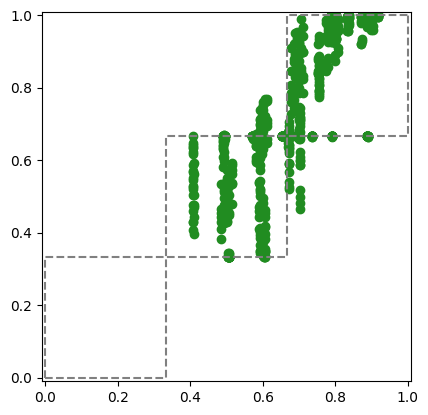

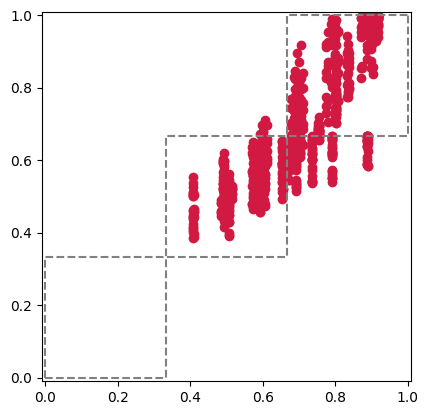

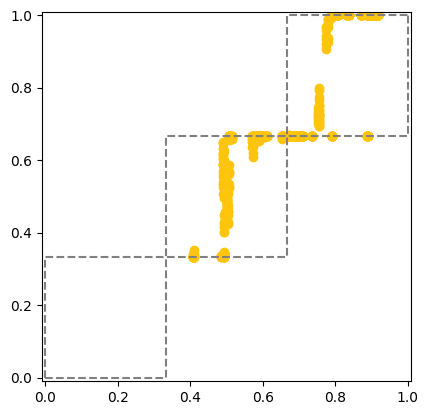

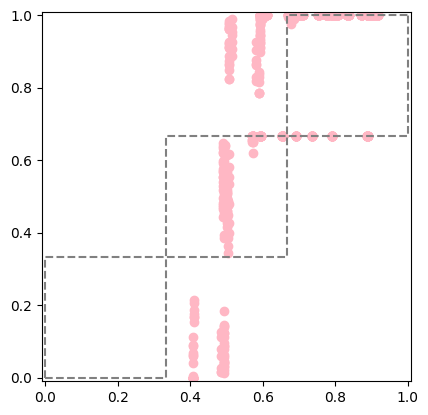

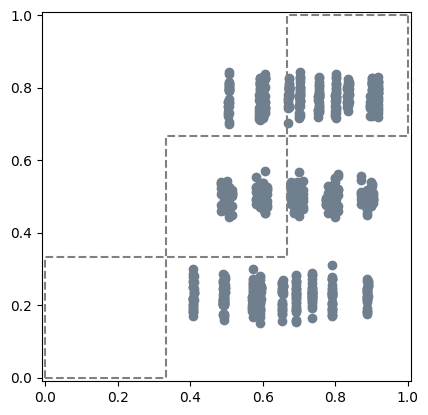

In [8]:
N_SEATS = 3
for election_type in AllowedRule:
    rule_df = df.query("method == @election_type")
    _, ax = plt.subplots()

    all_x_values = []
    all_y_values = []
    for pat in tqdm(all_settings_strings):
        filtered = rule_df[rule_df["file"].str.contains(pat, regex=False, na=False)]
        all_x_values.append(float(filtered["expected_proportion"].iloc[0])) # They are all the same for a given setting
        all_y_values.append(float(filtered["observed_proportion"].values.mean()))

    ax.plot(all_x_values, all_y_values, color=rule_color_map[election_type], marker='o', linestyle='None')
    ax.step(
        np.linspace(0,1,N_SEATS+1),
        np.arange(0,1.1, 1/N_SEATS),
        linestyle = 'dashed',
        c='gray',
        where='pre'
    )
    ax.step(
        np.linspace(0,1,N_SEATS+1),
        np.arange(0,1.1, 1/N_SEATS),
        linestyle = 'dashed',
        c='gray',
        where='post'
    )
    ax.set_xlim(-0.01, 1.01)
    ax.set_ylim(-0.01, 1.01)
    ax.set_aspect("equal", adjustable="box")
    # plt.savefig(f"../plots/bt_plots/waterfall/{election_type}_waterfall.png", dpi=300, bbox_inches='tight')

In [9]:
import math
N_SEATS = 3
election_type = "plurality"

rule_df = df.loc[df.query("method == @election_type").index]
rule_df["base_settings"] = rule_df["file"].str.rsplit("/", n=1).str[0]
rule_df.drop(columns=["file", "method", "disprop"], inplace=True)
group_df = rule_df.groupby("base_settings").aggregate({"expected_proportion": "mean", "observed_proportion": "mean"})
group_df.reset_index(inplace=True)
group_df["cand_counts"] = group_df["base_settings"].str.split("/").str[1]
group_df["b_proportion"] = group_df["base_settings"].str.split("b_proportion_").str[1].str.split("_").str[0].astype(float)
group_df["alphas"] = group_df["base_settings"].str.split("ALPHA_").str[1].str.split("_").str[0]
group_df["cohesions"] = group_df["base_settings"].str.split("COHESION_").str[1]

group_df


box_1 = (0.0, 0.33)
box_2 = (math.nextafter(0.33, 1.0), 0.66)
box_3 = (math.nextafter(0.66, 1.0), 1.0)
boxes = [box_1, box_2, box_3]

def in_box(exp_prop, obs_prop, box):
    return box[0] <= exp_prop <= box[1] and box[0] <= obs_prop <= box[1]


bad_locs = []
for idx, row in group_df.iterrows():
    exp_prop = row["expected_proportion"]
    obs_prop = row["observed_proportion"]
    for box in boxes:
        if in_box(exp_prop, obs_prop, box):
            break
    else:
        bad_locs.append(idx)


group_df.rename(columns={"expected_proportion": "expected_support", "observed_proportion": "observed_support"}, inplace=True)
group_df.drop(columns=["base_settings"]).iloc[bad_locs].to_csv("plurality_bt_proportionality_violation_settings.csv", index=False)





In [10]:
group_df

,base_settings,expected_support,observed_support,cand_counts,b_proportion,alphas,cohesions
0,preference_profiles/02_06/b_proportion_0.5__AL...,0.588840,0.603333,02_06,0.5,"(0.50,0.50,0.50,0.50)","(0.70,0.70)"
1,preference_profiles/02_06/b_proportion_0.5__AL...,0.591371,0.590000,02_06,0.5,"(0.50,0.50,0.50,0.50)","(0.70,0.90)"
2,preference_profiles/02_06/b_proportion_0.5__AL...,0.503641,0.553333,02_06,0.5,"(0.50,0.50,0.50,0.50)","(0.90,0.70)"
3,preference_profiles/02_06/b_proportion_0.5__AL...,0.506172,0.506667,02_06,0.5,"(0.50,0.50,0.50,0.50)","(0.90,0.90)"
4,preference_profiles/02_06/b_proportion_0.5__AL...,0.588840,0.588333,02_06,0.5,"(0.50,1.00,0.50,1.00)","(0.70,0.70)"
...,...,...,...,...,...,...,...
835,preference_profiles/08_02/b_proportion_0.9__AL...,0.888889,0.636667,08_02,0.9,"(2.00,1.00,2.00,1.00)","(0.90,0.90)"
836,preference_profiles/08_02/b_proportion_0.9__AL...,0.734940,0.646667,08_02,0.9,"(2.00,2.00,2.00,2.00)","(0.70,0.70)"
837,preference_profiles/08_02/b_proportion_0.9__AL...,0.888982,0.666667,08_02,0.9,"(2.00,2.00,2.00,2.00)","(0.70,0.90)"
838,preference_profiles/08_02/b_proportion_0.9__AL...,0.734847,0.666667,08_02,0.9,"(2.00,2.00,2.00,2.00)","(0.90,0.70)"
